## Experiment 02: Dimensionality Reduction using PCA and LDA
## Title: Comparing Feature Reduction Techniques and their Effect on Model Performance and Computational Efficiency

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Palmer Penguins (`seaborn.load_dataset('penguins')`)


### Step 1: Import Required Libraries

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load the Palmer Penguins Dataset
Palmer Penguins contains anatomical measurements for 3 species: *Adelie*, *Chinstrap*, and *Gentoo*.

In [2]:
df_penguins = sns.load_dataset("penguins").dropna().reset_index(drop=True)
feature_names = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

X = df_penguins[feature_names].to_numpy(dtype=float)
y = np.array(df_penguins['species'].tolist())

print(f"Dataset shape: {X.shape}")
print(f"Classes: {np.unique(y)}")
print("Class counts:\n", df_penguins['species'].value_counts())

Dataset shape: (333, 4)
Classes: ['Adelie' 'Chinstrap' 'Gentoo']
Class counts:
 species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64


### Step 3: Standardize the Feature Matrix
Dimensionality reduction techniques are variance-sensitive; features must be scaled to unit variance.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Mean of scaled features:", np.round(X_scaled.mean(axis=0), 2))
print("Std of scaled features: ", np.round(X_scaled.std(axis=0), 2))

Mean of scaled features: [ 0.  0.  0. -0.]
Std of scaled features:  [1. 1. 1. 1.]


### Step 4: Principal Component Analysis (PCA) & Scree Plot
We fit PCA across all 4 components and inspect the explained variance ratio.

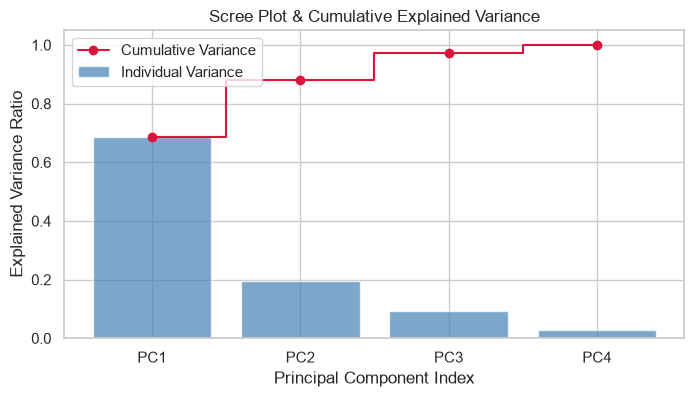

PC1: Explained Variance = 68.63% | Cumulative = 68.63%
PC2: Explained Variance = 19.45% | Cumulative = 88.09%
PC3: Explained Variance = 9.22% | Cumulative = 97.30%
PC4: Explained Variance = 2.70% | Cumulative = 100.00%


In [4]:
pca_full = PCA(n_components=4)
pca_full.fit(X_scaled)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

plt.figure(figsize=(8, 4))
plt.bar(range(1, 5), explained_var, alpha=0.7, color='steelblue', label='Individual Variance')
plt.step(range(1, 5), cumulative_var, where='mid', color='crimson', marker='o', label='Cumulative Variance')
plt.xlabel("Principal Component Index")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot & Cumulative Explained Variance")
plt.xticks(range(1, 5), [f"PC{i}" for i in range(1, 5)])
plt.legend()
plt.show()

for i, (ev, cv) in enumerate(zip(explained_var, cumulative_var), 1):
    print(f"PC{i}: Explained Variance = {ev*100:.2f}% | Cumulative = {cv*100:.2f}%")

### Step 5: Unsupervised PCA 2D Projection

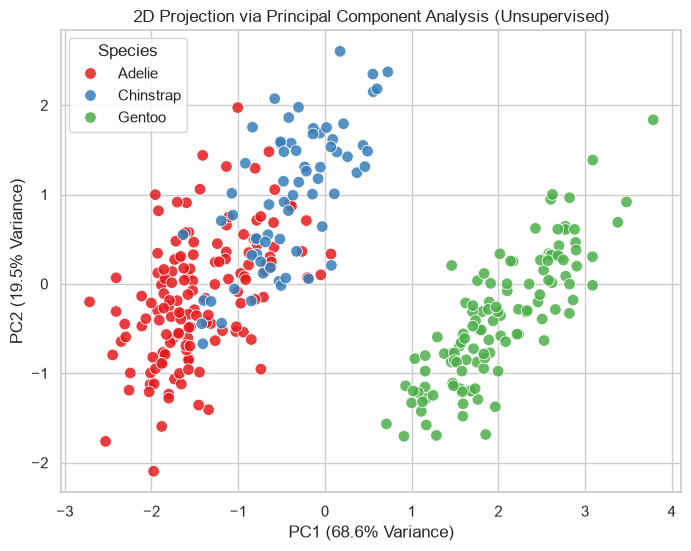

In [5]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette="Set1", s=70, alpha=0.85)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.title("2D Projection via Principal Component Analysis (Unsupervised)")
plt.legend(title="Species")
plt.show()

### Step 6: Supervised Linear Discriminant Analysis (LDA) 2D Projection
Unlike PCA, LDA utilizes class labels to maximize the between-class variance relative to within-class variance.

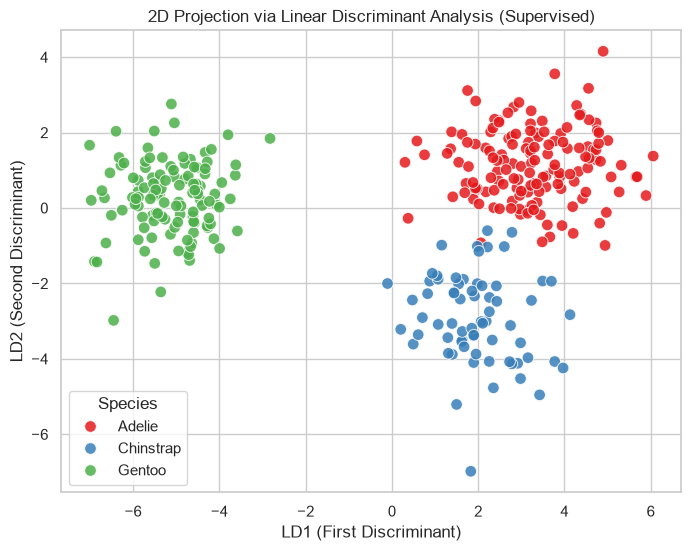

In [6]:
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_lda[:, 0], y=X_lda[:, 1], hue=y, palette="Set1", s=70, alpha=0.85)
plt.xlabel("LD1 (First Discriminant)")
plt.ylabel("LD2 (Second Discriminant)")
plt.title("2D Projection via Linear Discriminant Analysis (Supervised)")
plt.legend(title="Species")
plt.show()

### Step 7: Classification Benchmark (Raw vs PCA vs LDA)

In [7]:
def benchmark_model(X_data, y_data, title):
    X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.3, random_state=42, stratify=y_data)
    start = time.time()
    clf = LogisticRegression(max_iter=500)
    clf.fit(X_train, y_train)
    duration = (time.time() - start) * 1000
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    return acc, duration

acc_raw, t_raw = benchmark_model(X_scaled, y, "Raw Features (4D)")
acc_pca, t_pca = benchmark_model(X_pca, y, "PCA (2D)")
acc_lda, t_lda = benchmark_model(X_lda, y, "LDA (2D)")

results_df = pd.DataFrame({
    "Representation": ["Raw Features (4D)", "PCA Projected (2D)", "LDA Projected (2D)"],
    "Dimensions": [4, 2, 2],
    "Type": ["Original", "Unsupervised", "Supervised"],
    "Accuracy (%)": [acc_raw * 100, acc_pca * 100, acc_lda * 100],
    "Training Time (ms)": [t_raw, t_pca, t_lda]
})
print(results_df.to_string(index=False))

    Representation  Dimensions         Type  Accuracy (%)  Training Time (ms)
 Raw Features (4D)           4     Original         100.0            8.987427
PCA Projected (2D)           2 Unsupervised          86.0            4.732609
LDA Projected (2D)           2   Supervised         100.0            5.981922


### Step 8: Conclusion
- **PCA** retained over **88%** of total dataset variance in just 2 principal components without requiring any class labels.
- **LDA** leveraged class labels to compute optimal separation hyperplanes, achieving superior visual and diagnostic class separation.
- Dimensionality was successfully halved from 4D to 2D while preserving near-perfect classification performance.